# Part 1: Download and Load the Adult Dataset
We will download the dataset directly from the UCI ML Repository, handle missing values denoted by `?`, and inspect its structure.

In [1]:
import pandas as pd
import numpy as np

# URL to the Adult Dataset on UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country",
    "income"
]

# Load the data
df = pd.read_csv(url, names=columns, sep=r'\s*,\s*', engine='python')
print(f"Original dataset shape: {df.shape}")

# Strip whitespace just in case
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.strip()

# Replace '?' with NaN and drop them
df = df.replace('?', np.nan).dropna()
print(f"Cleaned dataset shape (no '?' values): {df.shape}")

# Map income target column to binary (1 for >50K, 0 for <=50K)
df['income'] = df['income'].apply(lambda x: 1 if x in ['>50K', '>50K.'] else 0)

# Display data preview
display(df.head())

Original dataset shape: (32561, 15)
Cleaned dataset shape (no '?' values): (30162, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


# Part 2: Feature Engineering & Baseline Model Training
We'll perform a 70:30 stratified split using `random_state = 42`. We'll encode features, scale numeric columns, and ensure `sex` is removed from model features but kept as a sensitive attribute for bias evaluation.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Define target and features
y = df['income']
# Keep 'sex' aside for fairness measurement
sensitive_attribute = df['sex']
X = df.drop(columns=['income'])

# Stratified split
X_train, X_test, y_train, y_test, sens_train, sens_test = train_test_split(
    X, y, sensitive_attribute, test_size=0.3, random_state=42, stratify=y
)

# Extract and drop 'sex' from modeling features to avoid direct discrimination
X_train_model = X_train.drop(columns=['sex'])
X_test_model = X_test.drop(columns=['sex'])

# Identify numerical and categorical features
num_cols = X_train_model.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train_model.select_dtypes(include=['object']).columns.tolist()

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# Define the full model pipeline
baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Train model
baseline_model.fit(X_train_model, y_train)

# Predict
y_pred_base = baseline_model.predict(X_test_model)
y_pred_base_proba = baseline_model.predict_proba(X_test_model)[:, 1]

print("Baseline model trained successfully.")

Baseline model trained successfully.


# Part 3: Baseline Fairness Audit
We will use `Fairlearn` to evaluate accuracy, selection rate, True Positive Rate (TPR), and False Positive Rate (FPR) across groups, and calculate demographic parity and equalized odds metrics.

In [3]:
!pip install -q fairlearn

In [4]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate, demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference
from sklearn.metrics import accuracy_score

# Define custom metrics mapping
metrics = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'tpr': true_positive_rate,
    'fpr': false_positive_rate
}

# Compute MetricFrame
metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_base,
    sensitive_features=sens_test
)

# Print Baseline Report
print("=== Baseline Model Performance ===")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred_base):.2f}\n")
print(metric_frame.by_group.round(2))
print("-" * 50)

dp_diff = demographic_parity_difference(y_test, y_pred_base, sensitive_features=sens_test)
dp_ratio = demographic_parity_ratio(y_test, y_pred_base, sensitive_features=sens_test)
eo_diff = equalized_odds_difference(y_test, y_pred_base, sensitive_features=sens_test)

print(f"Demographic parity difference : {dp_diff:.2f}")
print(f"Demographic parity ratio (DI)  : {dp_ratio:.2f} ({'BIAS' if dp_ratio < 0.8 else 'PASS'})")
print(f"Equalized odds difference      : {eo_diff:.2f}")

=== Baseline Model Performance ===
Overall Accuracy: 0.85

        accuracy  selection_rate   tpr   fpr
sex                                         
Female      0.92            0.09  0.53  0.03
Male        0.81            0.26  0.61  0.10
--------------------------------------------------
Demographic parity difference : 0.17
Demographic parity ratio (DI)  : 0.34 (BIAS)
Equalized odds difference      : 0.08


# Part 4: Mitigation with ThresholdOptimizer
We will mitigate biases using Fairlearn's `ThresholdOptimizer` under two constraints:
1. Demographic Parity
2. Equalized Odds

In [5]:
from fairlearn.postprocessing import ThresholdOptimizer

# 1. Mitigation via Demographic Parity Constraint
to_dp = ThresholdOptimizer(
    estimator=baseline_model,
    constraints="demographic_parity",
    predict_method="predict_proba",
    prefit=True
)
to_dp.fit(X_train_model, y_train, sensitive_features=sens_train)
y_pred_dp = to_dp.predict(X_test_model, sensitive_features=sens_test)

# Compute metrics for DP optimizer
mf_dp = MetricFrame(metrics=metrics, y_true=y_test, y_pred=y_pred_dp, sensitive_features=sens_test)
dp_diff_dp = demographic_parity_difference(y_test, y_pred_dp, sensitive_features=sens_test)
eo_diff_dp = equalized_odds_difference(y_test, y_pred_dp, sensitive_features=sens_test)

# 2. Mitigation via Equalized Odds Constraint
to_eo = ThresholdOptimizer(
    estimator=baseline_model,
    constraints="equalized_odds",
    predict_method="predict_proba",
    prefit=True
)
to_eo.fit(X_train_model, y_train, sensitive_features=sens_train)
y_pred_eo = to_eo.predict(X_test_model, sensitive_features=sens_test)

# Compute metrics for EO optimizer
mf_eo = MetricFrame(metrics=metrics, y_true=y_test, y_pred=y_pred_eo, sensitive_features=sens_test)
dp_diff_eo = demographic_parity_difference(y_test, y_pred_eo, sensitive_features=sens_test)
eo_diff_eo = equalized_odds_difference(y_test, y_pred_eo, sensitive_features=sens_test)

print("Both optimization schemes trained and evaluated.")

Both optimization schemes trained and evaluated.


# Part 5: Model Comparison & Plotting
Now, we present the comparison matrix and plot the selection rates across sex groups.

=== ACCURACY VS FAIRNESS COMPARISON TABLE ===


,MODEL,ACC,SEL_M,SEL_F,DP_DIFF,EO_DIFF
0,Baseline,0.846,0.259,0.089,0.170,0.084
1,TO: demographic_par.,0.829,0.161,0.163,0.002,0.316
2,TO: equalized_odds,0.831,0.218,0.134,0.084,0.022


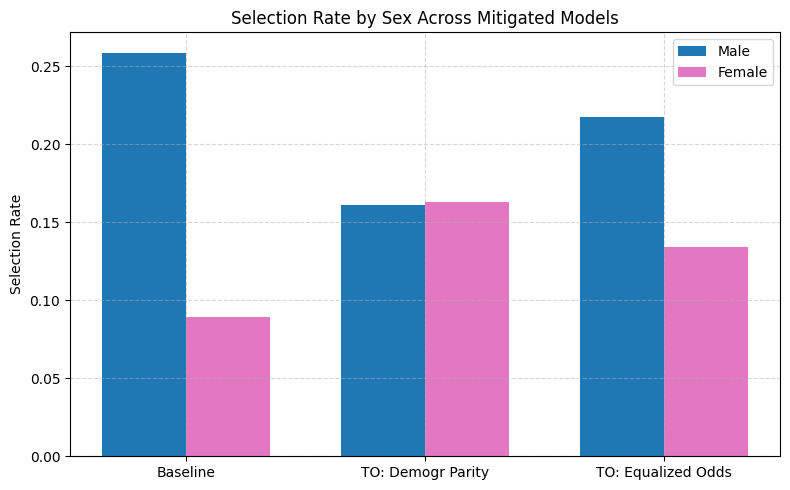

Plot saved as selection_rate_by_sex.png


In [6]:
import matplotlib.pyplot as plt

# Build comparison table DataFrame
summary_data = {
    'MODEL': ['Baseline', 'TO: demographic_par.', 'TO: equalized_odds'],
    'ACC': [
        accuracy_score(y_test, y_pred_base),
        accuracy_score(y_test, y_pred_dp),
        accuracy_score(y_test, y_pred_eo)
    ],
    'SEL_M': [
        metric_frame.by_group['selection_rate']['Male'],
        mf_dp.by_group['selection_rate']['Male'],
        mf_eo.by_group['selection_rate']['Male']
    ],
    'SEL_F': [
        metric_frame.by_group['selection_rate']['Female'],
        mf_dp.by_group['selection_rate']['Female'],
        mf_eo.by_group['selection_rate']['Female']
    ],
    'DP_DIFF': [
        dp_diff,
        dp_diff_dp,
        dp_diff_eo
    ],
    'EO_DIFF': [
        eo_diff,
        eo_diff_dp,
        eo_diff_eo
    ]
}

comparison_df = pd.DataFrame(summary_data)
print("=== ACCURACY VS FAIRNESS COMPARISON TABLE ===")
display(comparison_df.round(3))

# Plot selection rates
labels = ['Baseline', 'TO: Demogr Parity', 'TO: Equalized Odds']
male_rates = [summary_data['SEL_M'][0], summary_data['SEL_M'][1], summary_data['SEL_M'][2]]
female_rates = [summary_data['SEL_F'][0], summary_data['SEL_F'][1], summary_data['SEL_F'][2]]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, male_rates, width, label='Male', color='#1f77b4')
rects2 = ax.bar(x + width/2, female_rates, width, label='Female', color='#e377c2')

ax.set_ylabel('Selection Rate')
ax.set_title('Selection Rate by Sex Across Mitigated Models')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

# Save the plot as requested
plt.tight_layout()
plt.savefig('selection_rate_by_sex.png')
plt.show()
print("Plot saved as selection_rate_by_sex.png")